In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

df = pd.read_csv(url, sep=r"\s+", header=None)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (1000, 21)


,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [2]:
column_names = [
    "checking_account", "duration", "credit_history",
    "purpose", "credit_amount", "savings_account",
    "employment", "installment_rate", "personal_status",
    "other_debtors", "residence_since", "property",
    "age", "other_installment_plans", "housing",
    "existing_credits", "job", "dependents",
    "telephone", "foreign_worker", "credit_risk"
]

df.columns = column_names

print("Dataset Shape:", df.shape)
display(df.head())
print("\nColumn Information:")
df.info()

Dataset Shape: (1000, 21)


,checking_account,duration,credit_history,purpose,credit_amount,savings_account,employment,installment_rate,personal_status,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2



Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   checking_account         1000 non-null   object
 1   duration                 1000 non-null   int64 
 2   credit_history           1000 non-null   object
 3   purpose                  1000 non-null   object
 4   credit_amount            1000 non-null   int64 
 5   savings_account          1000 non-null   object
 6   employment               1000 non-null   object
 7   installment_rate         1000 non-null   int64 
 8   personal_status          1000 non-null   object
 9   other_debtors            1000 non-null   object
 10  residence_since          1000 non-null   int64 
 11  property                 1000 non-null   object
 12  age                      1000 non-null   int64 
 13  other_installment_plans  1000 non-null   object
 14  housing             

In [3]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df["credit_risk"].value_counts())

Missing Values:
checking_account           0
duration                   0
credit_history             0
purpose                    0
credit_amount              0
savings_account            0
employment                 0
installment_rate           0
personal_status            0
other_debtors              0
residence_since            0
property                   0
age                        0
other_installment_plans    0
housing                    0
existing_credits           0
job                        0
dependents                 0
telephone                  0
foreign_worker             0
credit_risk                0
dtype: int64

Duplicate Rows: 0

Target Distribution:
credit_risk
1    700
2    300
Name: count, dtype: int64


In [4]:
df["approval"] = df["credit_risk"].map({1: 1, 2: 0})
df = df.drop(columns=["credit_risk"])

print(df["approval"].value_counts())

approval
1    700
0    300
Name: count, dtype: int64


In [5]:
X = df.drop(columns=["approval"])
y = df["approval"]

numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical Columns:", numerical_cols)
print("\nCategorical Columns:", categorical_cols)
print("\nNumerical:", len(numerical_cols))
print("Categorical:", len(categorical_cols))

Numerical Columns: ['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'dependents']

Categorical Columns: ['checking_account', 'credit_history', 'purpose', 'savings_account', 'employment', 'personal_status', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']

Numerical: 7
Categorical: 13


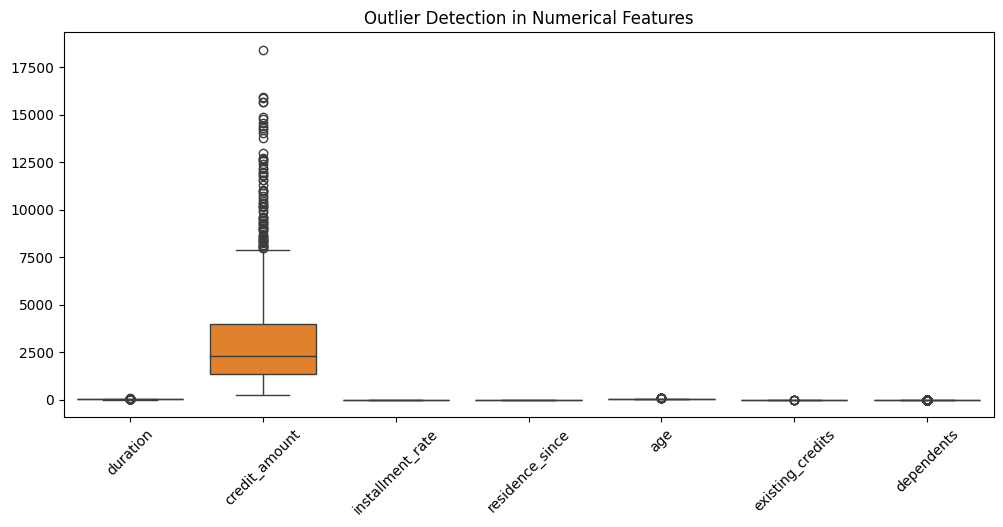

In [6]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=X[numerical_cols])
plt.xticks(rotation=45)
plt.title("Outlier Detection in Numerical Features")
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=145,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 700
Testing samples: 300


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (700, 61)
Testing shape: (300, 61)


In [9]:
import statsmodels.api as sm
import numpy as np

# Convert processed data to dense arrays if necessary
X_train_lr = X_train_processed
X_test_lr = X_test_processed

if hasattr(X_train_lr, "toarray"):
    X_train_lr = X_train_lr.toarray()
    X_test_lr = X_test_lr.toarray()

# Add intercept for OLS
X_train_lr = sm.add_constant(X_train_lr, has_constant="add")
X_test_lr = sm.add_constant(X_test_lr, has_constant="add")

# Train Linear Regression using OLS
linear_model = sm.OLS(y_train.to_numpy(), X_train_lr).fit()

# Generate predictions
linear_predictions = linear_model.predict(X_test_lr)

print("Linear Regression completed!")
print("R-squared:", linear_model.rsquared)
print("Median prediction:", np.median(linear_predictions))

Linear Regression completed!
R-squared: 0.2918661882805368
Median prediction: 0.7125332119943675


/tmp/ipykernel_3606/147654892.py:17: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  linear_model = sm.OLS(y_train.to_numpy(), X_train_lr).fit()


In [10]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=145
)

logistic_model.fit(X_train_processed, y_train)

logistic_probabilities = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

logistic_predictions = (
    logistic_probabilities >= 0.5
).astype(int)

print("Logistic Regression completed!")
print("First 10 probabilities:")
print(logistic_probabilities[:10])

Logistic Regression completed!
First 10 probabilities:
[0.87321854 0.93087918 0.75534702 0.97888197 0.95679916 0.27472422
 0.84027394 0.72911312 0.32444816 0.75060822]


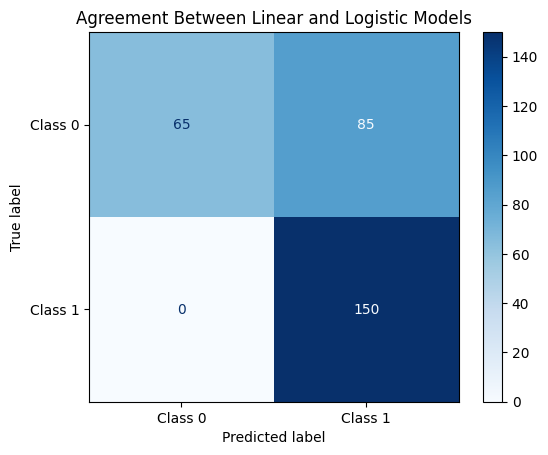

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

median_threshold = np.median(linear_predictions)

linear_classes = (
    linear_predictions >= median_threshold
).astype(int)

logistic_classes = (
    logistic_probabilities >= 0.5
).astype(int)

# Compare the two models
comparison_matrix = confusion_matrix(
    linear_classes,
    logistic_classes,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=comparison_matrix,
    display_labels=["Class 0", "Class 1"]
)

disp.plot(cmap="Blues")
plt.title("Agreement Between Linear and Logistic Models")
plt.show()

In [12]:
mismatch_count = np.sum(
    linear_classes != logistic_classes
)

total_cases = len(y_test)

mismatch_percentage = (
    mismatch_count / total_cases
) * 100

print("Median Linear Prediction:", median_threshold)
print("Logistic Threshold: 0.5")
print("Total Test Cases:", total_cases)
print("Mismatched Cases:", mismatch_count)
print("Mismatch Percentage:", round(mismatch_percentage, 2), "%")

Median Linear Prediction: 0.7125332119943675
Logistic Threshold: 0.5
Total Test Cases: 300
Mismatched Cases: 85
Mismatch Percentage: 28.33 %


In [13]:
#part 2
df["age_group"] = np.where(
    df["age"] < 30,
    "Below 30",
    "30 and Above"
)

print(df["age_group"].value_counts())

print("\nApproval rate by age group:")
print(
    df.groupby("age_group")["approval"].mean() * 100
)

age_group
30 and Above    629
Below 30        371
Name: count, dtype: int64

Approval rate by age group:
age_group
30 and Above    74.085851
Below 30        63.072776
Name: approval, dtype: float64


In [14]:
import statsmodels.api as sm
import pandas as pd

features = [
    "duration",
    "credit_amount",
    "installment_rate",
    "age",
    "existing_credits",
    "dependents"
]

def fit_subgroup_model(data):
    X_sub = sm.add_constant(
        data[features].astype(float),
        has_constant="add"
    )
    y_sub = data["approval"]

    model = sm.Logit(y_sub, X_sub).fit(disp=False)
    return model

full_model = fit_subgroup_model(df)

group_a = df[df["age_group"] == "Below 30"]
group_b = df[df["age_group"] == "30 and Above"]

model_a = fit_subgroup_model(group_a)
model_b = fit_subgroup_model(group_b)

print("All three models trained successfully!")

All three models trained successfully!


In [15]:
comparison = pd.DataFrame({
    "Full Dataset": full_model.params,
    "Below 30": model_a.params,
    "30 and Above": model_b.params
})

print("Regression Coefficients:")
display(comparison.round(4))

print("\nDuration Confidence Intervals:")

for name, model in [
    ("Full Dataset", full_model),
    ("Below 30", model_a),
    ("30 and Above", model_b)
]:
    ci = model.conf_int().loc["duration"]

    print(
        name,
        "| Coefficient:", round(model.params["duration"], 4),
        "| 95% CI:", tuple(ci.round(4))
    )

Regression Coefficients:


,Full Dataset,Below 30,30 and Above
const,1.5028,0.6295,2.4575
duration,-0.0263,-0.0263,-0.0270
credit_amount,-0.0001,-0.0001,-0.0001
installment_rate,-0.2046,-0.2632,-0.1956
age,0.0204,0.0814,-0.0021
existing_credits,0.1526,-0.1693,0.3087
dependents,-0.1308,-0.2276,-0.3068



Duration Confidence Intervals:
Full Dataset | Coefficient: -0.0263 | 95% CI: (-0.0414, -0.0113)
Below 30 | Coefficient: -0.0263 | 95% CI: (-0.0513, -0.0012)
30 and Above | Coefficient: -0.027 | 95% CI: (-0.0462, -0.0077)


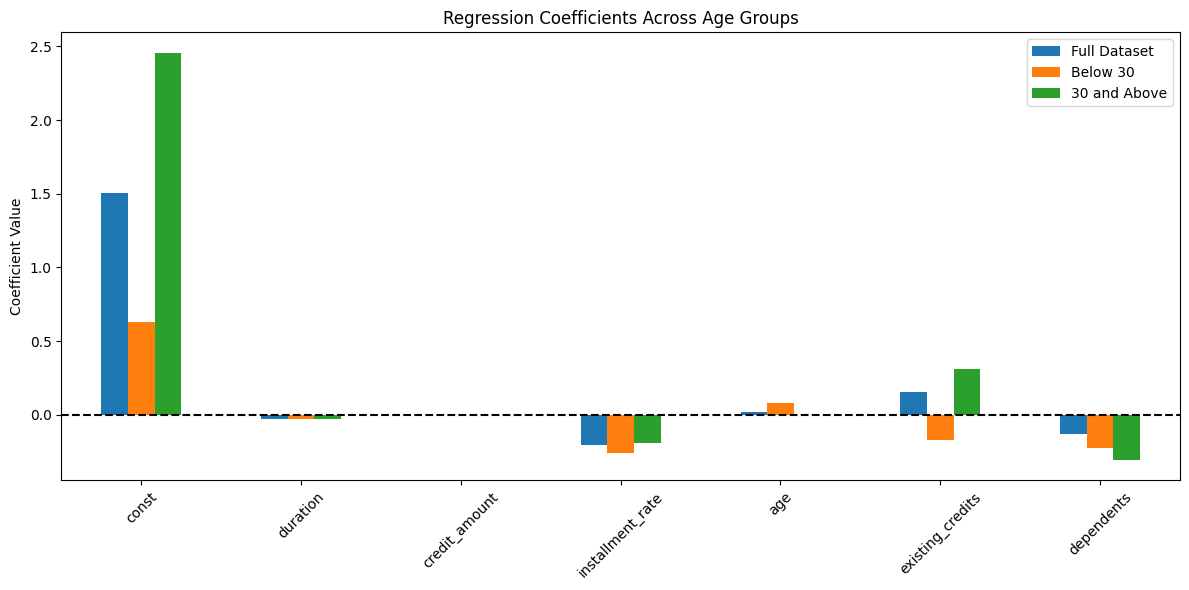

In [16]:
comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.axhline(0, color="black", linestyle="--")
plt.title("Regression Coefficients Across Age Groups")
plt.ylabel("Coefficient Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
#comapring
for name, model in [
    ("Full Dataset", full_model),
    ("Below 30", model_a),
    ("30 and Above", model_b)
]:
    ci = model.conf_int().loc["existing_credits"]

    print(f"\n{name}")
    print("Coefficient:", round(model.params["existing_credits"], 4))
    print("95% CI:", tuple(ci.round(4)))
    print("P-value:", round(model.pvalues["existing_credits"], 5))


Full Dataset
Coefficient: 0.1526
95% CI: (-0.1029, 0.4081)
P-value: 0.24184

Below 30
Coefficient: -0.1693
95% CI: (-0.6197, 0.2811)
P-value: 0.46118

30 and Above
Coefficient: 0.3087
95% CI: (-0.0131, 0.6305)
P-value: 0.06006


In [18]:
import statsmodels.formula.api as smf

interaction_model = smf.logit(
    formula=(
        "approval ~ duration + credit_amount + "
        "installment_rate + age + dependents + "
        "existing_credits * C(age_group)"
    ),
    data=df
).fit(disp=False)

print("Interaction test results:")
print(
    interaction_model.summary2().tables[1][
        ["Coef.", "P>|z|", "[0.025", "0.975]"]
    ]
)

Interaction test results:
                                              Coef.     P>|z|    [0.025  \
Intercept                                  2.416067  0.000040  1.262505   
C(age_group)[T.Below 30]                  -0.029763  0.944602 -0.869273   
duration                                  -0.026933  0.000489 -0.042074   
credit_amount                             -0.000069  0.042739 -0.000136   
installment_rate                          -0.212972  0.003527 -0.356037   
age                                        0.001329  0.887843 -0.017144   
dependents                                -0.287560  0.168016 -0.696384   
existing_credits                           0.301375  0.067014 -0.021125   
existing_credits:C(age_group)[T.Below 30] -0.428938  0.119384 -0.968761   

                                             0.975]  
Intercept                                  3.569629  
C(age_group)[T.Below 30]                   0.809746  
duration                                  -0.011792  
credit_

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np


def create_model(feature_data):

    num_cols = feature_data.select_dtypes(
        include=["number"]
    ).columns.tolist()

    cat_cols = feature_data.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    preprocessing = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_cols),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols)
    ])

    model = Pipeline([
        ("preprocessor", preprocessing),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=145
        ))
    ])

    return model

full_bias_model = create_model(X_train)
full_bias_model.fit(X_train, y_train)

X_train_reduced = X_train.drop(columns=["age"])

reduced_bias_model = create_model(X_train_reduced)
reduced_bias_model.fit(X_train_reduced, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [20]:
def get_coefficients(model):

    feature_names = model.named_steps[
        "preprocessor"
    ].get_feature_names_out()

    coefficients = model.named_steps[
        "classifier"
    ].coef_[0]

    return pd.Series(
        coefficients,
        index=feature_names
    )

full_coef = get_coefficients(full_bias_model)
reduced_coef = get_coefficients(reduced_bias_model)

print("Full model features:", len(full_coef))
print("Reduced model features:", len(reduced_coef))

Full model features: 61
Reduced model features: 60


In [21]:
predictors = [
    "num__duration",
    "num__credit_amount",
    "num__installment_rate",
    "num__existing_credits"
]

bias_comparison = pd.DataFrame({
    "Full Model": full_coef[predictors],
    "Reduced Model": reduced_coef[predictors]
})

bias_comparison["Percentage Change"] = (
    (
        bias_comparison["Reduced Model"]
        - bias_comparison["Full Model"]
    )
    / bias_comparison["Full Model"].abs()
) * 100

display(bias_comparison.round(4))

,Full Model,Reduced Model,Percentage Change
num__duration,-0.3526,-0.3660,-3.7976
num__credit_amount,-0.2632,-0.2593,1.5053
num__installment_rate,-0.3481,-0.3449,0.9367
num__existing_credits,-0.2015,-0.1907,5.3458


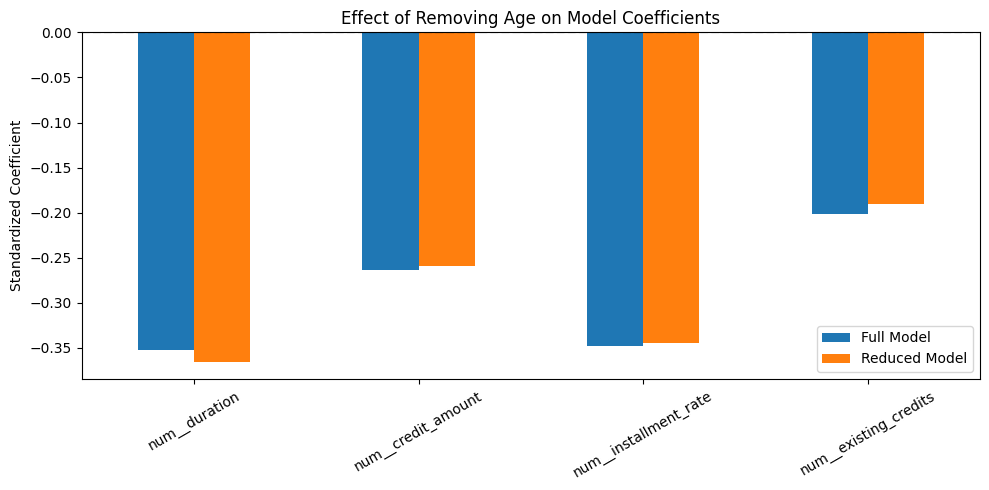

In [22]:
bias_comparison[
    ["Full Model", "Reduced Model"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Effect of Removing Age on Model Coefficients")
plt.ylabel("Standardized Coefficient")
plt.xticks(rotation=30)
plt.axhline(0, color="black", linestyle="--")
plt.tight_layout()
plt.show()

In [23]:


import numpy as np
import pandas as pd
probabilities = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

actual = y_test.to_numpy()


false_positive = (
    (probabilities >= 0.75) &
    (actual == 0)
)

false_negative = (
    (probabilities <= 0.25) &
    (actual == 1)
)

wrong_mask = false_positive | false_negative


wrong_cases = X_test.loc[wrong_mask].copy()

wrong_cases["actual_approval"] = actual[wrong_mask]
wrong_cases["predicted_probability"] = probabilities[wrong_mask]

print("Total Test Cases:", len(X_test))
print("High-confidence False Positives:", false_positive.sum())
print("High-confidence False Negatives:", false_negative.sum())
print("Total High-confidence Errors:", wrong_mask.sum())

error_percentage = wrong_mask.mean() * 100

print("Error Percentage:", round(error_percentage, 2), "%")

Total Test Cases: 300
High-confidence False Positives: 20
High-confidence False Negatives: 4
Total High-confidence Errors: 24
Error Percentage: 8.0 %


In [24]:

sample_size = min(50, len(wrong_cases))

if sample_size > 0:
    adversarial_subset = wrong_cases.sample(
        n=sample_size,
        random_state=145
    )
else:
    adversarial_subset = wrong_cases.copy()

print("Adversarial Subset Size:", len(adversarial_subset))

display(adversarial_subset.head(10))

Adversarial Subset Size: 24


,checking_account,duration,credit_history,purpose,credit_amount,savings_account,employment,installment_rate,personal_status,other_debtors,...,age,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,actual_approval,predicted_probability
896,A11,21,A32,A43,2606,A61,A72,4,A92,A101,...,28,A143,A151,1,A174,1,A192,A201,1,0.188641
552,A11,48,A32,A43,6999,A61,A74,1,A94,A103,...,34,A143,A152,2,A173,1,A192,A201,0,0.821746
980,A12,30,A34,A42,8386,A61,A74,2,A93,A101,...,49,A143,A152,1,A173,1,A191,A201,0,0.905215
580,A12,18,A34,A40,1056,A61,A75,3,A93,A103,...,30,A141,A152,2,A173,1,A191,A201,0,0.837470
304,A14,48,A34,A40,10127,A63,A73,2,A93,A101,...,44,A141,A153,1,A173,1,A191,A201,0,0.765038
56,A12,12,A32,A43,6468,A65,A71,2,A93,A101,...,52,A143,A152,1,A174,1,A192,A201,0,0.865226
141,A12,36,A32,A43,4795,A61,A72,4,A92,A101,...,30,A143,A152,1,A174,1,A192,A201,1,0.221461
118,A11,33,A34,A42,4281,A63,A73,1,A92,A101,...,23,A143,A152,2,A173,1,A191,A201,0,0.785837
861,A14,18,A33,A49,2169,A61,A73,4,A94,A101,...,28,A143,A152,1,A173,1,A192,A201,0,0.886124
614,A14,18,A33,A42,1808,A61,A74,4,A92,A101,...,22,A143,A152,1,A173,1,A191,A201,0,0.965995


In [25]:
# Comparing age
full_test_age = X_test["age"]
adversarial_age = adversarial_subset["age"]

age_comparison = pd.DataFrame({
    "Full Test Set": [
        full_test_age.mean(),
        full_test_age.median()
    ],
    "Adversarial Subset": [
        adversarial_age.mean(),
        adversarial_age.median()
    ]
}, index=["Mean Age", "Median Age"])

display(age_comparison.round(2))

full_age_groups = pd.cut(
    full_test_age,
    bins=[0, 30, 45, np.inf],
    labels=["Below 30", "30-45", "Above 45"],
    right=False
)

subset_age_groups = pd.cut(
    adversarial_age,
    bins=[0, 30, 45, np.inf],
    labels=["Below 30", "30-45", "Above 45"],
    right=False
)

age_distribution = pd.DataFrame({
    "Full Test Set (%)":
        full_age_groups.value_counts(normalize=True) * 100,
    "Adversarial Subset (%)":
        subset_age_groups.value_counts(normalize=True) * 100
})

display(age_distribution.round(2))

,Full Test Set,Adversarial Subset
Mean Age,35.48,34.0
Median Age,33.00,30.0


,Full Test Set (%),Adversarial Subset (%)
age,,
Below 30,38.33,45.83
30-45,42.67,37.50
Above 45,19.00,16.67


In [26]:

traits = {
    "Long Loan Duration (>= 24 months)":
        adversarial_subset["duration"] >= 24,

    "High Credit Amount (>= 5000)":
        adversarial_subset["credit_amount"] >= 5000,

    "Age Below 30":
        adversarial_subset["age"] < 30,

    "Multiple Existing Credits":
        adversarial_subset["existing_credits"] >= 2,

    "High Installment Rate (>= 4)":
        adversarial_subset["installment_rate"] >= 4
}

trait_results = pd.DataFrame({
    trait: {
        "Count": int(condition.sum()),
        "Percentage": round(condition.mean() * 100, 2)
    }
    for trait, condition in traits.items()
}).T

trait_results = trait_results.sort_values(
    by="Percentage",
    ascending=False
)

display(trait_results)

,Count,Percentage
High Installment Rate (>= 4),13.0,54.17
Multiple Existing Credits,12.0,50.00
Age Below 30,11.0,45.83
Long Loan Duration (>= 24 months),10.0,41.67
High Credit Amount (>= 5000),5.0,20.83


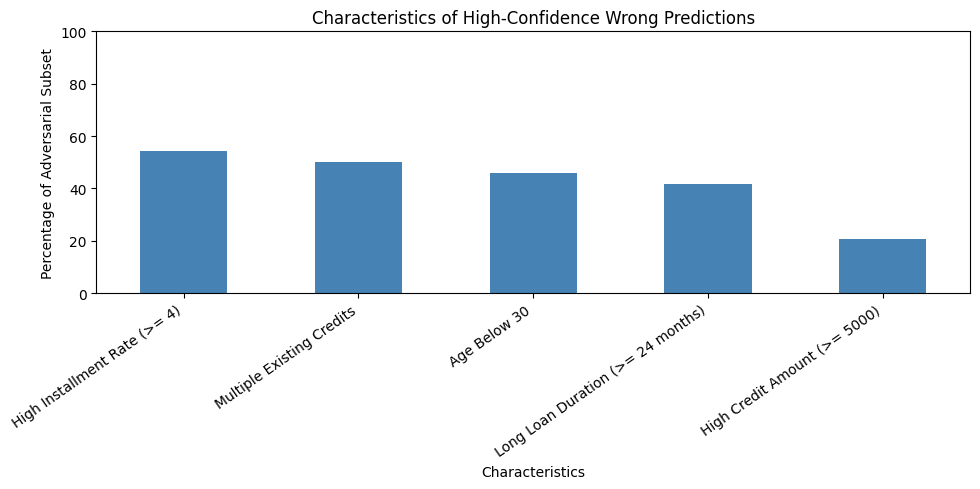

In [27]:
import matplotlib.pyplot as plt

trait_results["Percentage"].plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue"
)

plt.title("Characteristics of High-Confidence Wrong Predictions")
plt.ylabel("Percentage of Adversarial Subset")
plt.xlabel("Characteristics")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [28]:
trait_conditions = {
    "High Installment Rate": lambda d: d["installment_rate"] >= 4,
    "Multiple Existing Credits": lambda d: d["existing_credits"] >= 2,
    "Age Below 30": lambda d: d["age"] < 30,
    "Long Loan Duration": lambda d: d["duration"] >= 24,
    "High Credit Amount": lambda d: d["credit_amount"] >= 5000
}

comparison_rows = []

for name, condition in trait_conditions.items():
    full_pct = condition(X_test).mean() * 100
    subset_pct = condition(adversarial_subset).mean() * 100

    comparison_rows.append({
        "Characteristic": name,
        "Full Test (%)": round(full_pct, 2),
        "Adversarial (%)": round(subset_pct, 2),
        "Difference (pp)": round(subset_pct - full_pct, 2)
    })

trait_comparison = pd.DataFrame(comparison_rows)
display(trait_comparison)

,Characteristic,Full Test (%),Adversarial (%),Difference (pp)
0,High Installment Rate,46.33,54.17,7.83
1,Multiple Existing Credits,34.67,50.00,15.33
2,Age Below 30,38.33,45.83,7.50
3,Long Loan Duration,39.33,41.67,2.33
4,High Credit Amount,19.00,20.83,1.83


In [31]:
#fairness trade off


import numpy as np
import pandas as pd

y_true = y_test.to_numpy()
y_prob = logistic_probabilities

group_a = (X_test["age"].to_numpy() < 30)
group_b = ~group_a

def safe_ratio(a, b):
    if np.isnan(a) or np.isnan(b) or b == 0:
        return np.nan
    return a / b

def calculate_group_metrics(actual, predicted):

    tp = np.sum((actual == 1) & (predicted == 1))
    fp = np.sum((actual == 0) & (predicted == 1))
    tn = np.sum((actual == 0) & (predicted == 0))
    fn = np.sum((actual == 1) & (predicted == 0))

    approval_rate = np.mean(predicted == 1)

    tpr = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
    ppv = tp / (tp + fp) if (tp + fp) > 0 else np.nan

    return approval_rate, tpr, fpr, ppv

thresholds = np.round(np.arange(0.05, 0.96, 0.10), 2)

results = []

for t in thresholds:

    predictions = (y_prob >= t).astype(int)

    a = calculate_group_metrics(
        y_true[group_a],
        predictions[group_a]
    )

    b = calculate_group_metrics(
        y_true[group_b],
        predictions[group_b]
    )

    dp = safe_ratio(a[0], b[0])

    eo = min(
        safe_ratio(a[1], b[1]),
        safe_ratio(a[2], b[2])
    )

    pp = safe_ratio(a[3], b[3])

    accuracy = np.mean(predictions == y_true)

    results.append({
        "Threshold": t,
        "DP": dp,
        "EO": eo,
        "PP": pp,
        "Accuracy": accuracy
    })

fairness_df = pd.DataFrame(results)

display(fairness_df.round(4))

,Threshold,DP,EO,PP,Accuracy
0,0.05,1.0000,1.0000,0.7872,0.7000
1,0.15,0.9900,1.0000,0.7952,0.7200
2,0.25,0.9399,0.9075,0.8250,0.7333
3,0.35,0.8757,0.7877,0.8709,0.7567
4,0.45,0.8398,0.8824,0.8272,0.7533
5,0.55,0.7829,0.7572,0.8806,0.7567
6,0.65,0.7280,0.7048,0.8989,0.7433
7,0.75,0.7073,0.7826,0.9098,0.7233
8,0.85,0.6320,0.4783,0.9713,0.6100
9,0.95,0.5775,0.6812,0.9286,0.4700


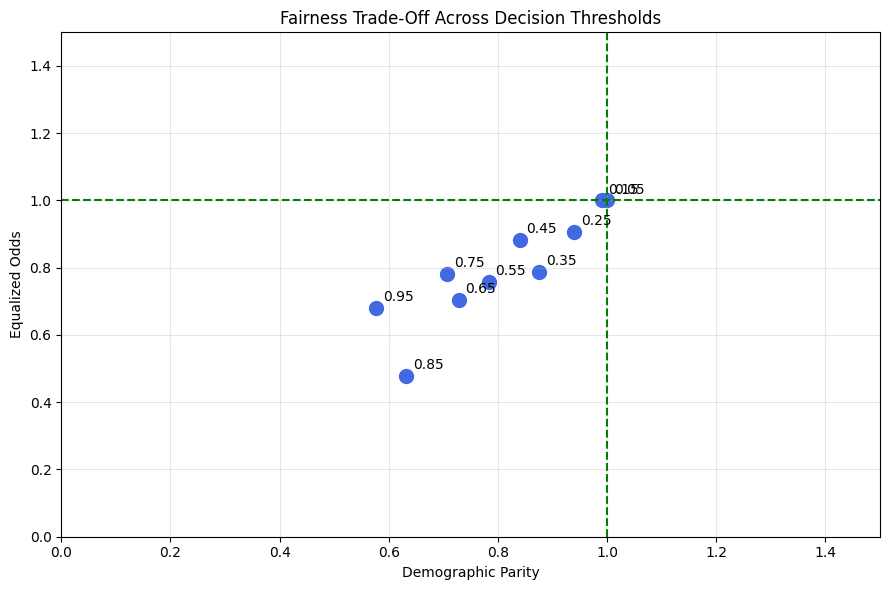

In [32]:
import matplotlib.pyplot as plt

valid = fairness_df.dropna(subset=["DP", "EO"])

plt.figure(figsize=(9, 6))

plt.scatter(
    valid["DP"],
    valid["EO"],
    s=100,
    color="royalblue"
)

for _, row in valid.iterrows():
    plt.annotate(
        f'{row["Threshold"]:.2f}',
        (row["DP"], row["EO"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axvline(1, color="green", linestyle="--")
plt.axhline(1, color="green", linestyle="--")

plt.xlabel("Demographic Parity")
plt.ylabel("Equalized Odds")
plt.title("Fairness Trade-Off Across Decision Thresholds")

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
print("FAIRNESS ANALYSIS SUMMARY")

print("\nThreshold with DP closest to 1:")
dp_row = fairness_df.iloc[
    (fairness_df["DP"] - 1).abs().idxmin()
]
display(dp_row.to_frame().T.round(4))

print("\nThreshold with EO closest to 1:")
eo_row = fairness_df.iloc[
    (fairness_df["EO"] - 1).abs().idxmin()
]
display(eo_row.to_frame().T.round(4))

print("\nThreshold with PP closest to 1:")
pp_row = fairness_df.iloc[
    (fairness_df["PP"] - 1).abs().idxmin()
]
display(pp_row.to_frame().T.round(4))

FAIRNESS ANALYSIS SUMMARY

Threshold with DP closest to 1:


,Threshold,DP,EO,PP,Accuracy
0,0.05,1.0,1.0,0.7872,0.7



Threshold with EO closest to 1:


,Threshold,DP,EO,PP,Accuracy
0,0.05,1.0,1.0,0.7872,0.7



Threshold with PP closest to 1:


,Threshold,DP,EO,PP,Accuracy
8,0.85,0.632,0.4783,0.9713,0.61


In [34]:
# Test whether age groups have different effects
interaction_terms = [
    col for col in interaction_model.params.index
    if "existing_credits:C(age_group)" in col
]

for term in interaction_terms:
    print("Interaction term:", term)
    print("Coefficient:", round(interaction_model.params[term], 4))
    print("P-value:", round(interaction_model.pvalues[term], 5))
    print("95% CI:",
          tuple(interaction_model.conf_int().loc[term].round(4)))

Interaction term: existing_credits:C(age_group)[T.Below 30]
Coefficient: -0.4289
P-value: 0.11938
95% CI: (-0.9688, 0.1109)


In [35]:
# Compare two thresholds
row_85 = fairness_df.loc[
    np.isclose(fairness_df["Threshold"], 0.85)
].iloc[0]

row_65 = fairness_df.loc[
    np.isclose(fairness_df["Threshold"], 0.65)
].iloc[0]

dp_gain = (
    (row_65["DP"] - row_85["DP"])
    / row_85["DP"]
) * 100

eo_gain = (
    (row_65["EO"] - row_85["EO"])
    / row_85["EO"]
) * 100

print("DP improvement:", round(dp_gain, 2), "%")
print("EO improvement:", round(eo_gain, 2), "%")

DP improvement: 15.2 %
EO improvement: 47.37 %


In [36]:
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import pandas as pd

predictors = [
    "duration",
    "credit_amount",
    "installment_rate",
    "existing_credits",
    "dependents"
]

interaction_results = []

base_formula = (
    "approval ~ duration + credit_amount + "
    "installment_rate + age + "
    "existing_credits + dependents + C(age_group)"
)

for predictor in predictors:

    formula = (
        base_formula +
        f" + {predictor}:C(age_group)"
    )

    model = smf.logit(
        formula=formula,
        data=df
    ).fit(disp=False)

    term = [
        name for name in model.params.index
        if f"{predictor}:C(age_group)" in name
    ][0]

    interaction_results.append({
        "Predictor": predictor,
        "Coefficient": model.params[term],
        "P-value": model.pvalues[term]
    })

interaction_table = pd.DataFrame(interaction_results)

interaction_table["Adjusted P-value"] = multipletests(
    interaction_table["P-value"],
    method="fdr_bh"
)[1]

display(
    interaction_table.sort_values("P-value").round(5)
)

,Predictor,Coefficient,P-value,Adjusted P-value
3,existing_credits,-0.42894,0.11938,0.59692
1,credit_amount,-0.00005,0.33895,0.84739
0,duration,-0.00761,0.52919,0.88199
4,dependents,0.09947,0.86772,0.97750
2,installment_rate,-0.00377,0.97750,0.97750


In [37]:
row_35 = fairness_df.loc[
    np.isclose(fairness_df["Threshold"], 0.35)
].iloc[0]

row_45 = fairness_df.loc[
    np.isclose(fairness_df["Threshold"], 0.45)
].iloc[0]

dp_gain = (
    (row_35["DP"] - row_45["DP"])
    / row_45["DP"]
) * 100

eo_loss = (
    (row_45["EO"] - row_35["EO"])
    / row_45["EO"]
) * 100

tradeoff_cost = eo_loss / dp_gain

print("DP improvement:", round(dp_gain, 2), "%")
print("EO reduction:", round(eo_loss, 2), "%")
print("Trade-off cost:", round(tradeoff_cost, 2))

DP improvement: 4.28 %
EO reduction: 10.73 %
Trade-off cost: 2.5
